# Loan Default Prediction Using Machine Learning

**Student:** Luvisha Gaba  
**Roll Number:** 23MTS5720  
**Course:** B.Sc. Mathematical Science  
**Subject:** Machine Learning  
**Semester:** 7

## 1. Introduction

Loan default occurs when a borrower does not repay a loan according to the agreed terms. Identifying patterns linked with default can help a lender assess credit risk and decide which applications may need closer review.

This project uses classification algorithms to predict whether a borrower will default on a loan. The analysis includes data cleaning, exploratory data analysis, model training, validation, model comparison and final testing.

## 2. Aim and Objectives

**Aim:** To build and compare machine learning classification models for predicting loan default.

**Objectives**
- Understand the dataset and check its quality.
- Explore borrower and loan characteristics using EDA.
- Prepare numerical and categorical variables for modelling.
- Train Logistic Regression, XGBoost, K-Nearest Neighbours, Naive Bayes and Random Forest models.
- Compare the models using validation data.
- Select a suitable model and evaluate it on separate test data.

## 3. Dataset Description and Source

The project uses the **Loan Default Prediction** dataset published on Kaggle.

**Dataset source:** https://www.kaggle.com/datasets/nikhil1e9/loan-default  
**File used:** `Loan_default.csv`

The supplied file contains 255,347 rows and 18 columns. It includes borrower details, loan information and the outcome of each loan.

The target column is `Default`:
- `0` means the borrower did not default.
- `1` means the borrower defaulted.

`LoanID` is an identifier and is not used as a predictor because it does not represent a borrower or loan characteristic.

In [1]:
# Importing libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.base import clone

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 4. Loading the Dataset
The dataset is loaded using Pandas to examine the loan applicant details and identify patterns related to loan defaults.

In [2]:
import os

data_path = "data/Loan_default.csv"

if not os.path.exists(data_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        data_path = next(iter(uploaded))
    except Exception:
        data_path = input("Enter the path to Loan_default.csv: ").strip()

df = pd.read_csv(data_path)

print("Dataset loaded.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded.
Rows and columns: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## 5. Understanding and Cleaning the Data

The first checks show the data types, missing values, duplicate records and summary statistics. The target is checked separately because the project is a binary classification task.

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe(include="all").T)

if "Default" not in df.columns:
    raise ValueError("The dataset must contain a 'Default' column.")

# Removing exact duplicate rows, if any.
df = df.drop_duplicates().copy()

# Checking that the target contains two valid classes.
print("Target values:", sorted(df["Default"].dropna().unique()))
df = df.dropna(subset=["Default"]).copy()
df["Default"] = df["Default"].astype(int)

if not set(df["Default"].unique()).issubset({0, 1}):
    raise ValueError("Default must contain only 0 and 1.")

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  

,Missing values
LoanID,0
Age,0
Income,0
LoanAmount,0
CreditScore,0
MonthsEmployed,0
NumCreditLines,0
InterestRate,0
LoanTerm,0
DTIRatio,0



Number of duplicate rows: 0

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
LoanID,255347,255347,I38PQUQS96,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,255347.0,NaN,NaN,NaN,43.498306,14.990258,18.0,31.0,43.0,56.0,69.0
Income,255347.0,NaN,NaN,NaN,82499.304597,38963.013729,15000.0,48825.5,82466.0,116219.0,149999.0
LoanAmount,255347.0,NaN,NaN,NaN,127578.865512,70840.706142,5000.0,66156.0,127556.0,188985.0,249999.0
CreditScore,255347.0,NaN,NaN,NaN,574.264346,158.903867,300.0,437.0,574.0,712.0,849.0
MonthsEmployed,255347.0,NaN,NaN,NaN,59.541976,34.643376,0.0,30.0,60.0,90.0,119.0
NumCreditLines,255347.0,NaN,NaN,NaN,2.501036,1.117018,1.0,2.0,2.0,3.0,4.0
InterestRate,255347.0,NaN,NaN,NaN,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,NaN,NaN,NaN,36.025894,16.96933,12.0,24.0,36.0,48.0,60.0
DTIRatio,255347.0,NaN,NaN,NaN,0.500212,0.230917,0.1,0.3,0.5,0.7,0.9


Target values: [np.int64(0), np.int64(1)]


## 6. Exploratory Data Analysis (EDA)

EDA helps understand the distribution of the target and the relationship between borrower and loan characteristics. The charts describe patterns in this dataset; they do not prove that a particular feature causes default.

,Count,Percentage
Default,,
Non-default (0),225694,88.39
Default (1),29653,11.61


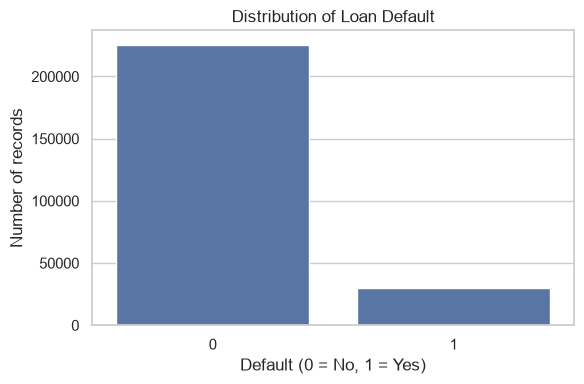

In [4]:
# Class distribution
target_counts = df["Default"].value_counts().sort_index()
target_percent = df["Default"].value_counts(normalize=True).sort_index() * 100

display(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
}).rename(index={0: "Non-default (0)", 1: "Default (1)"}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Default")
plt.title("Distribution of Loan Default")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

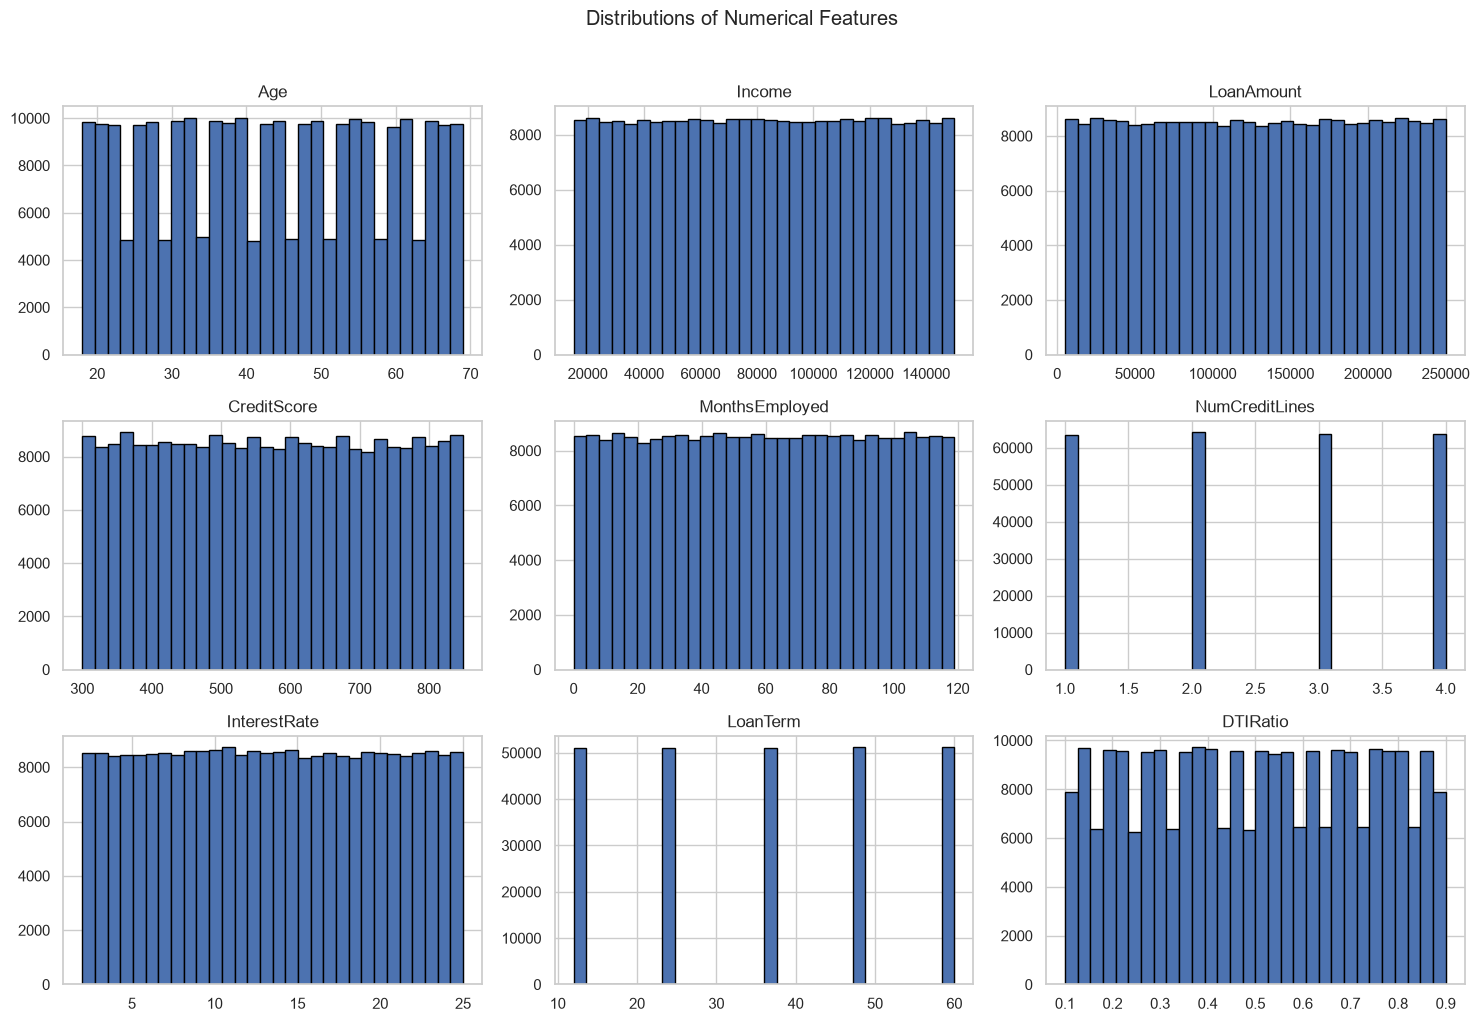

In [5]:
# Identifying feature types for EDA.
eda_df = df.drop(columns=["LoanID"], errors="ignore")
numeric_eda_cols = eda_df.select_dtypes(include=np.number).columns.drop("Default", errors="ignore")
categorical_eda_cols = eda_df.select_dtypes(exclude=np.number).columns.tolist()

# Numerical feature distributions
eda_df[numeric_eda_cols].hist(figsize=(15, 10), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

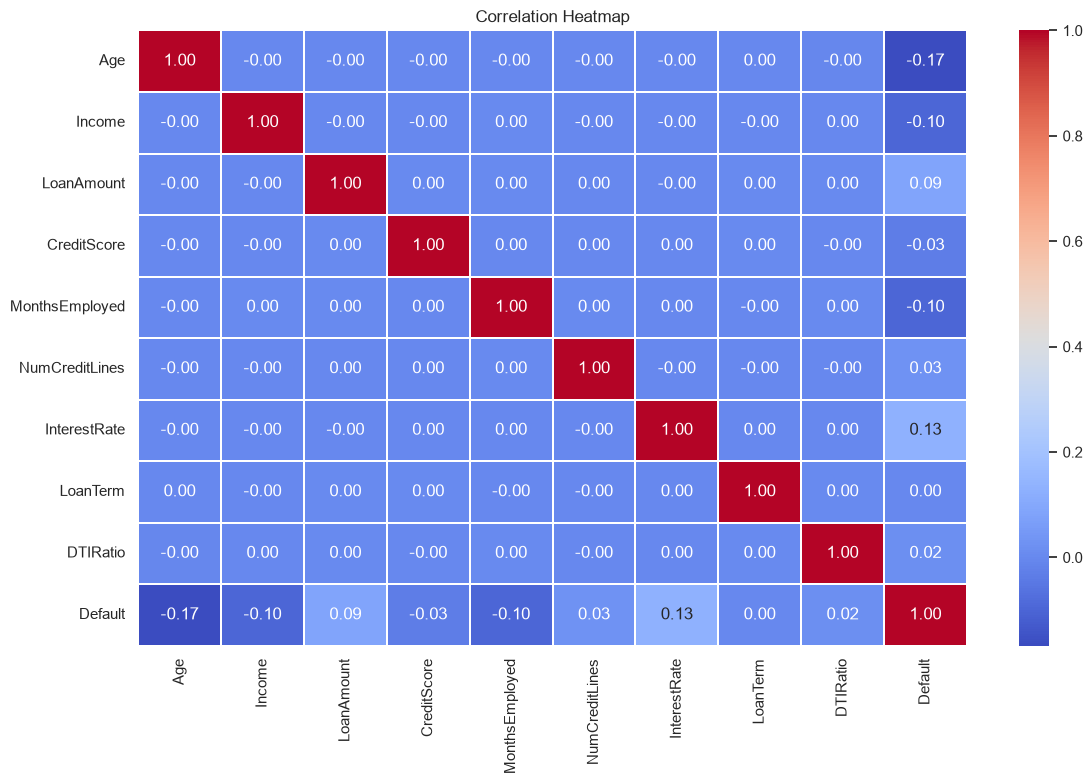

In [6]:
# Correlation heatmap for numerical variables
corr = eda_df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.3)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

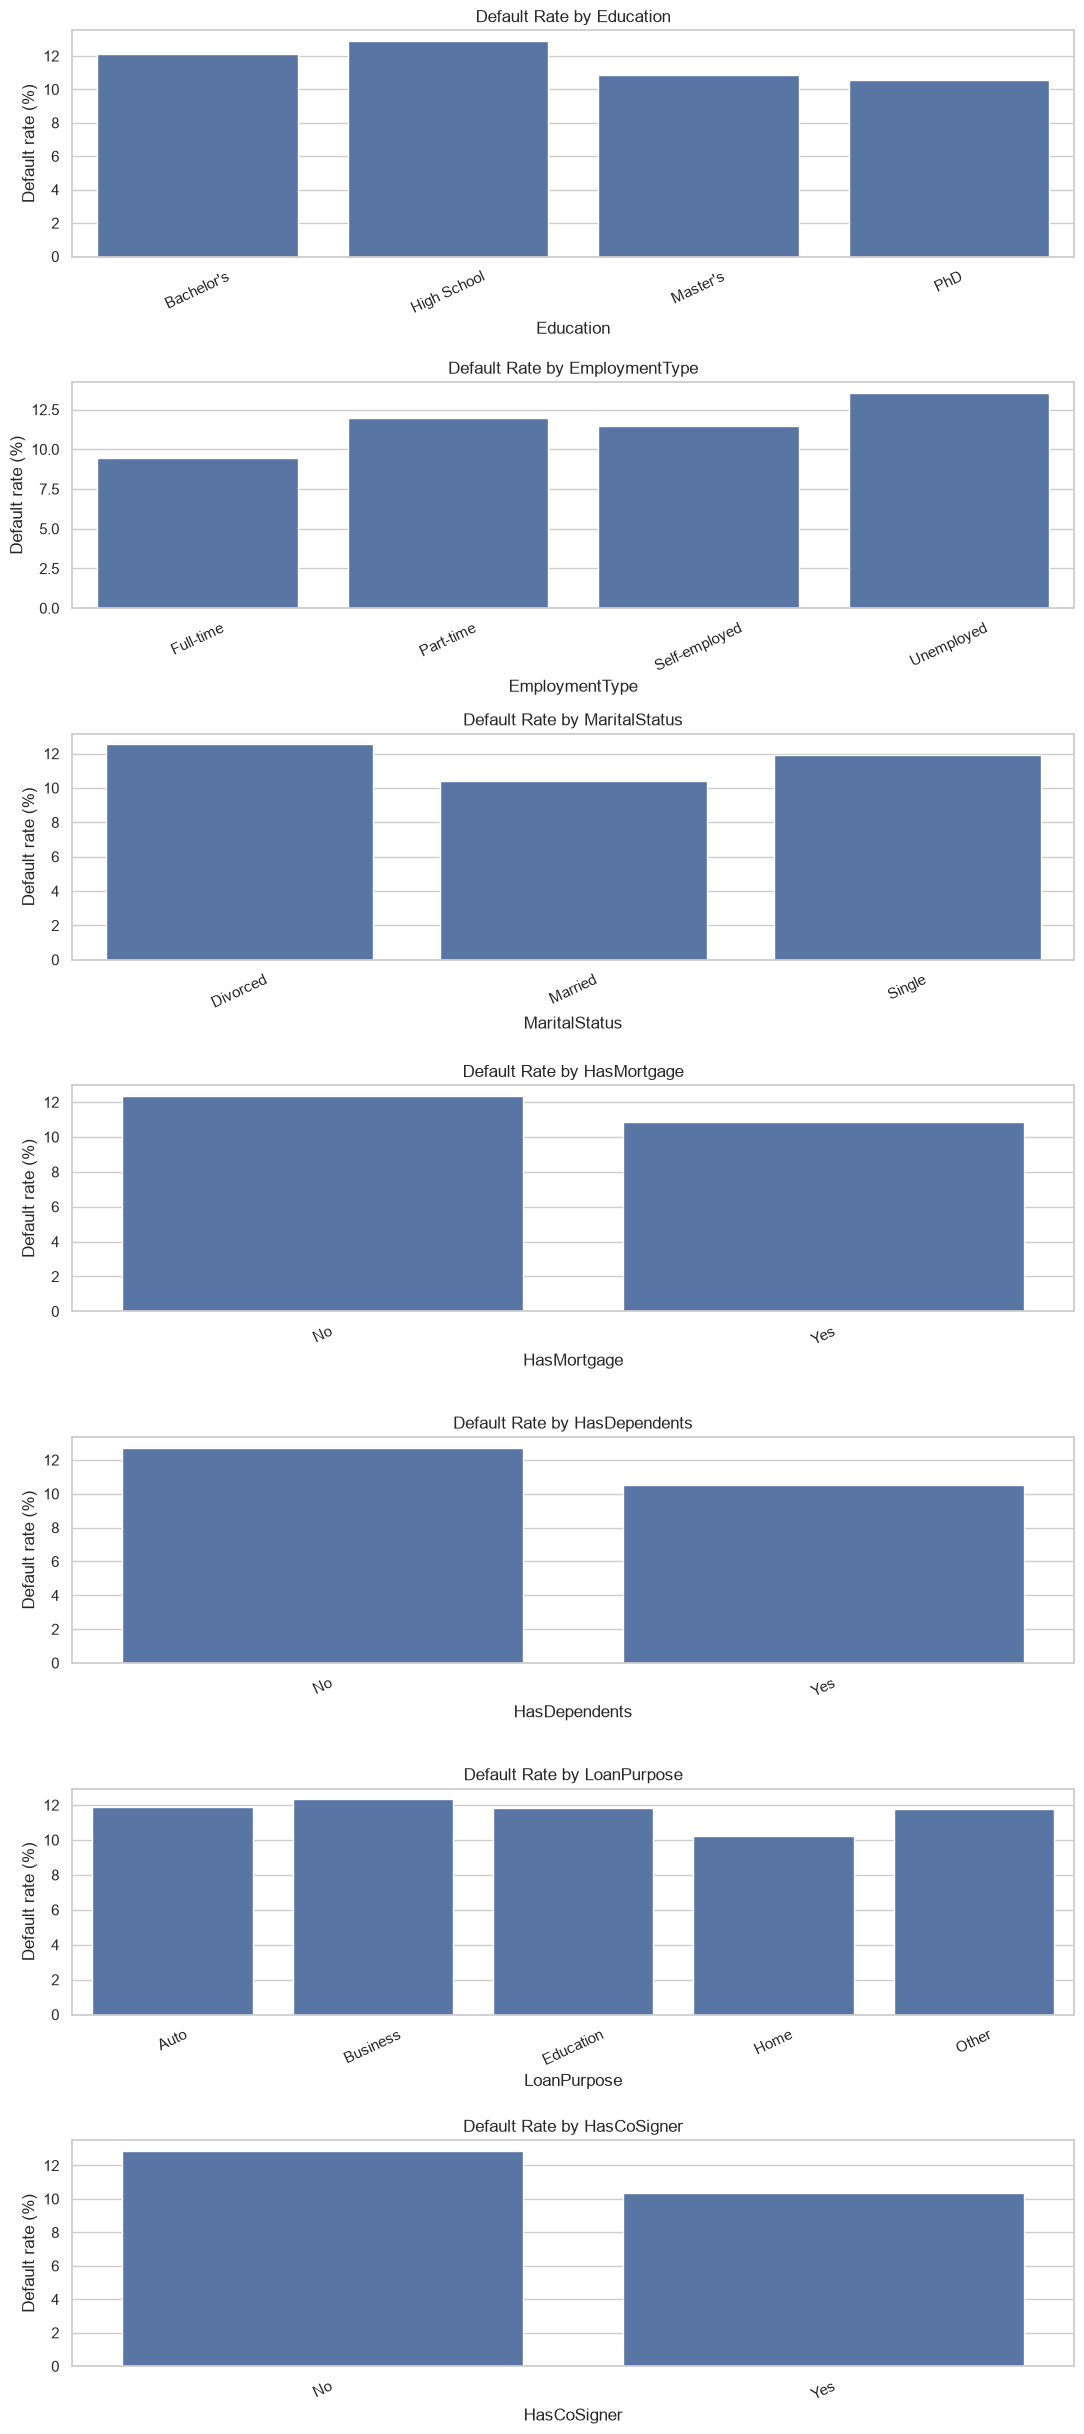

In [7]:
# Default rate across categorical features
if categorical_eda_cols:
    fig, axes = plt.subplots(
        len(categorical_eda_cols), 1,
        figsize=(11, 3.5 * len(categorical_eda_cols))
    )
    if len(categorical_eda_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, categorical_eda_cols):
        rates = eda_df.groupby(col, dropna=False)["Default"].mean().mul(100)
        sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax)
        ax.set_title(f"Default Rate by {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Default rate (%)")
        ax.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.show()

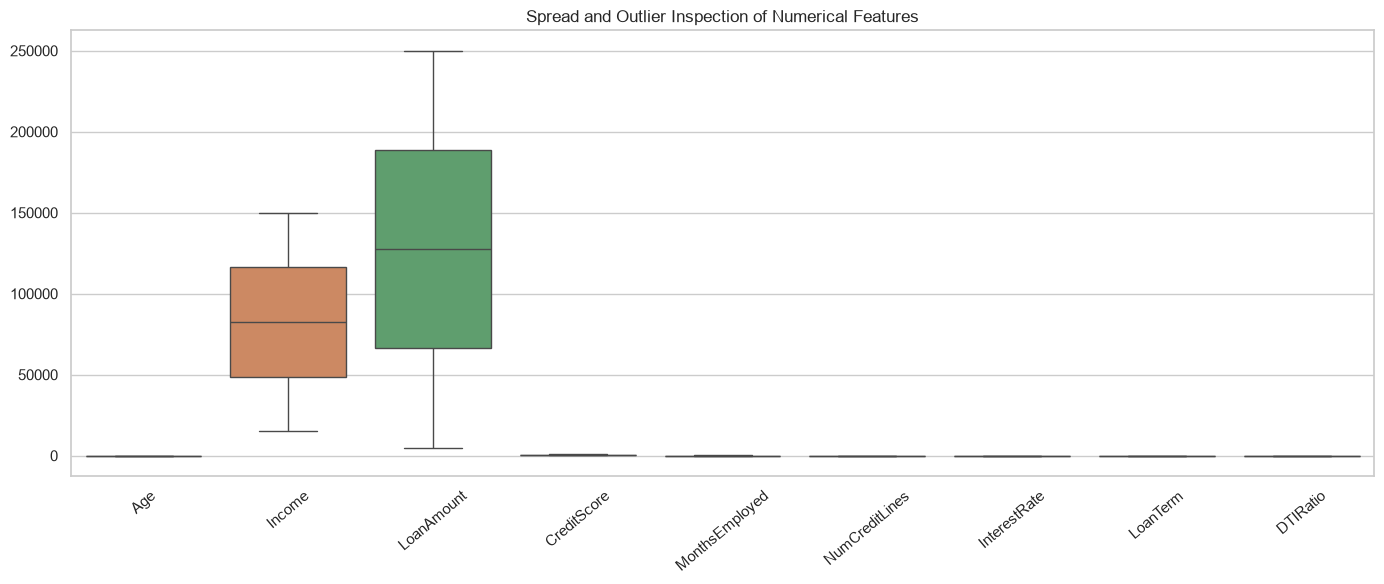

In [8]:
# Boxplots for numerical variables
plt.figure(figsize=(14, 6))
sns.boxplot(data=eda_df[numeric_eda_cols])
plt.title("Spread and Outlier Inspection of Numerical Features")
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

### 6.1 Observations from EDA

The target distribution is imbalanced: non-default cases form the larger group, while default cases are the minority. This matters because a model can achieve high accuracy by predicting the majority class more often, while still missing many actual defaults.

The histograms show the ranges and distributions of numerical variables. The correlation heatmap summarises linear relationships between numerical variables. The category-wise charts compare the observed default rate across groups. These results are useful for understanding the dataset before modelling.

The boxplots help identify unusually high or low values. An observation is not removed only because it appears as an outlier; it should be checked against the meaning and quality of the data.

## 7. Separating Features and Target

The `Default` column is the outcome to be predicted. All other useful columns are predictors. `LoanID` is removed because it is only an identifier.

In [9]:
model_data = df.drop(columns=["LoanID"], errors="ignore").copy()
X = model_data.drop(columns=["Default"])
y = model_data["Default"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Number of records:", len(X))
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Number of records: 255347
Numerical features: ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']
Categorical features: ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


## 8. Training, Validation and Test Split

The data is divided into three parts:

- **80% training data:** used to fit the models.
- **10% validation data:** used to compare the models and select one.
- **10% test data:** kept separate until the final evaluation.

Stratified splitting keeps approximately the same proportion of default and non-default cases in each set. The test data is not used to select the model.

In [10]:
# First set aside 20% for validation and testing.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Dividing the remaining 20% equally into validation and test sets.
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

split_summary = pd.DataFrame({
    "Records": [len(X_train), len(X_valid), len(X_test)],
    "Share of dataset (%)": [
        len(X_train) / len(X) * 100,
        len(X_valid) / len(X) * 100,
        len(X_test) / len(X) * 100
    ],
    "Default rate (%)": [
        y_train.mean() * 100,
        y_valid.mean() * 100,
        y_test.mean() * 100
    ]
}, index=["Training", "Validation", "Testing"])

display(split_summary.round(2))

,Records,Share of dataset (%),Default rate (%)
Training,204277,80.0,11.61
Validation,25535,10.0,11.62
Testing,25535,10.0,11.61


## 9. Data Preprocessing

Machine learning algorithms require numerical input. Numerical missing values are replaced with their median and then standardised. Categorical missing values are replaced with the most frequent category and converted into indicator columns using one-hot encoding.

The preprocessing steps are placed inside a pipeline. Each pipeline learns its imputation values, scaling values and category levels from the training data only. This prevents information from the validation and test sets from entering model training.

In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


## 10. Classification Models

Since the target variable has two categories (default and non-default), this is a **supervised binary classification** problem.

Five classification algorithms are compared:

1. **Logistic Regression:** estimates the probability of belonging to the default class using a logistic function.
2. **K-Nearest Neighbours (KNN):** predicts a class using the labels of the nearest training observations.
3. **Naive Bayes:** applies Bayes' theorem and assumes conditional independence between features.
4. **Random Forest:** combines predictions from multiple decision trees.
5. **XGBoost:** builds decision trees sequentially, with each new tree helping correct errors made by earlier trees.

The dataset is imbalanced, so the evaluation gives special attention to the precision and recall of the default class.


### 10.1 Logistic Regression

Logistic Regression is a classification algorithm that estimates the probability of an observation belonging to a class. It is used here as a baseline model. Class weighting gives additional importance to the minority default class during training.

In [12]:
logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','LoanAmount',...,'HasDependents','LoanPurpose', 'HasCoSigner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

### 10.2 K-Nearest Neighbours (KNN)

KNN compares a new observation with nearby observations in the training data. The most common class among its nearest neighbours is used for prediction. Scaling is important because KNN uses distances between observations.

To keep computation practical for this large dataset, KNN is fitted on a stratified sample of up to 30,000 training records. This limitation is kept in mind when comparing its results with the other models.

In [13]:
# Stratified sample for KNN to keep distance calculations manageable.
KNN_TRAIN_LIMIT = 30000

if len(X_train) > KNN_TRAIN_LIMIT:
    X_knn_train, _, y_knn_train, _ = train_test_split(
        X_train, y_train,
        train_size=KNN_TRAIN_LIMIT,
        random_state=RANDOM_STATE,
        stratify=y_train
    )
else:
    X_knn_train, y_knn_train = X_train, y_train

knn_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    ))
])

knn_model.fit(X_knn_train, y_knn_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','LoanAmount',...,'HasDependents','LoanPurpose', 'HasCoSigner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

### 10.3 Naive Bayes

Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem. Gaussian Naive Bayes is used because the dataset contains continuous numerical variables along with encoded categorical variables. The class priors are set equally to reduce the influence of the unequal class frequencies.

In [14]:
# GaussianNB requires a dense feature matrix.
nb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ],
    remainder="drop",
    sparse_threshold=0
)

naive_bayes_model = Pipeline(steps=[
    ("preprocessor", nb_preprocessor),
    ("classifier", GaussianNB(priors=[0.5, 0.5]))
])

naive_bayes_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','LoanAmount',...,'HasDependents','LoanPurpose', 'HasCoSigner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the tran

### 10.4 Random Forest

Random Forest is an ensemble method that combines several decision trees. Each tree is trained using a different sample of the data and a random selection of features. Combining the trees can capture non-linear patterns. Balanced class weights are used to account for the minority default class.

In [15]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','LoanAmount',...,'HasDependents','LoanPurpose', 'HasCoSigner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

### 10.5 XGBoost

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm that builds decision trees sequentially. Each new tree focuses on improving the errors made by the previous trees. It can capture complex, non-linear relationships and is widely used for structured/tabular datasets.

Since default cases are the minority class, `scale_pos_weight` is set using the ratio of non-default to default cases in the training data. The model uses the same training set and preprocessing pipeline as the other full-data models.


In [16]:
# XGBoost with class-imbalance adjustment.
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgboost_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=2,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgboost_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','LoanAmount',...,'HasDependents','LoanPurpose', 'HasCoSigner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

## 11. Validation and Model Comparison

All five models are evaluated on the same validation set. The KNN model uses the training sample described above; the other models use the full training set.

The metrics include:
- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** proportion of predicted defaults that are actual defaults.
- **Recall:** proportion of actual defaults correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** ability to rank positive cases above negative cases across thresholds.
- **Average precision:** summary of the precision-recall curve.

Recall is important in this project because a false negative means that an actual default was predicted as non-default. Precision is also important because too many false alarms can lead to unnecessary reviews.


In [17]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Naive Bayes": naive_bayes_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model
}

def evaluate_model(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_eval, predictions),
        "Default Precision": precision_score(y_eval, predictions, zero_division=0),
        "Default Recall": recall_score(y_eval, predictions, zero_division=0),
        "Default F1-score": f1_score(y_eval, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
        "Average Precision": average_precision_score(y_eval, probabilities)
    }

validation_results = {}
validation_probabilities = {}

for name, model in models.items():
    validation_results[name] = evaluate_model(model, X_valid, y_valid)
    validation_probabilities[name] = model.predict_proba(X_valid)[:, 1]

validation_comparison = pd.DataFrame(validation_results).T
display(validation_comparison.sort_values("Default F1-score", ascending=False).round(4))


,Accuracy,Default Precision,Default Recall,Default F1-score,ROC-AUC,Average Precision
XGBoost,0.7047,0.2297,0.6554,0.3402,0.7528,0.3307
Logistic Regression,0.6747,0.2170,0.6905,0.3303,0.7495,0.3130
Naive Bayes,0.6677,0.2123,0.6868,0.3244,0.7422,0.3038
Random Forest,0.8680,0.3957,0.2589,0.3130,0.7496,0.3210
KNN,0.8794,0.3523,0.0459,0.0811,0.6317,0.1875


## 12. Selecting the Best Model

The model is selected using its validation performance, not the test results. The default-class F1-score is used as the main selection measure because it balances precision and recall. ROC-AUC and average precision are also considered when interpreting the comparison.

The model with the highest validation F1-score is selected below. The validation results should be reviewed alongside the other metrics, especially default recall.

In [18]:
best_model_name = validation_comparison["Default F1-score"].idxmax()
best_model = models[best_model_name]

print("Selected model based on validation F1-score:", best_model_name)
print("\nValidation results for selected model:")
display(validation_comparison.loc[[best_model_name]].round(4))

Selected model based on validation F1-score: XGBoost

Validation results for selected model:


,Accuracy,Default Precision,Default Recall,Default F1-score,ROC-AUC,Average Precision
XGBoost,0.7047,0.2297,0.6554,0.3402,0.7528,0.3307


## 13. Final Testing

After selecting the model, its performance is measured on the test set. The test set was not used to fit the models or choose the best one, so it provides a separate estimate of performance on unseen records.

In [19]:
test_predictions = best_model.predict(X_test)
test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_metrics = evaluate_model(best_model, X_test, y_test)
test_results = pd.DataFrame([test_metrics], index=[best_model_name])

print("Final test results:")
display(test_results.round(4))

print("Classification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["Non-default", "Default"],
    zero_division=0
))

Final test results:


,Accuracy,Default Precision,Default Recall,Default F1-score,ROC-AUC,Average Precision
XGBoost,0.711,0.2376,0.6739,0.3513,0.7592,0.3282


Classification report:
              precision    recall  f1-score   support

 Non-default       0.94      0.72      0.81     22570
     Default       0.24      0.67      0.35      2965

    accuracy                           0.71     25535
   macro avg       0.59      0.69      0.58     25535
weighted avg       0.86      0.71      0.76     25535



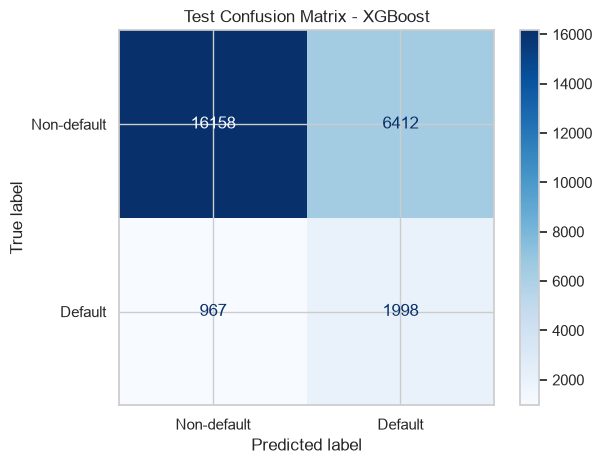

In [20]:
# Confusion matrix for the selected model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-default", "Default"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Test Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

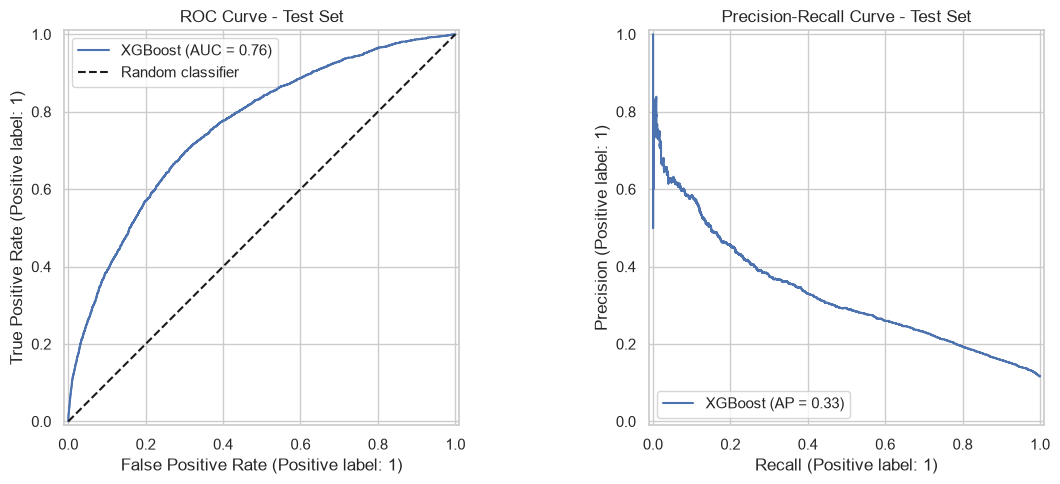

In [21]:
# ROC and precision-recall curves for the selected model
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_predictions(
    y_test, test_probabilities, ax=axes[0], name=best_model_name
)
axes[0].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[0].set_title("ROC Curve - Test Set")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(
    y_test, test_probabilities, ax=axes[1], name=best_model_name
)
axes[1].set_title("Precision-Recall Curve - Test Set")

plt.tight_layout()
plt.show()

## 14. Feature Importance

Feature importance is examined for both Random Forest and XGBoost. The values indicate how much each fitted model used an encoded feature when making predictions. They help identify influential predictors, but do not show that a feature causes loan default. The two models may rank features differently because they learn patterns in different ways.


,Feature,Random Forest Importance,XGBoost Importance
22,num__Age,0.1333,0.1170
26,num__InterestRate,0.1274,0.0668
25,num__Income,0.1174,0.0545
29,num__MonthsEmployed,0.0970,0.0478
11,cat__HasDependents_Yes,0.0065,0.0434
4,cat__EmploymentType_Full-time,0.0088,0.0418
9,cat__HasCoSigner_Yes,0.0064,0.0399
27,num__LoanAmount,0.1028,0.0399
10,cat__HasDependents_No,0.0066,0.0389
8,cat__HasCoSigner_No,0.0064,0.0384


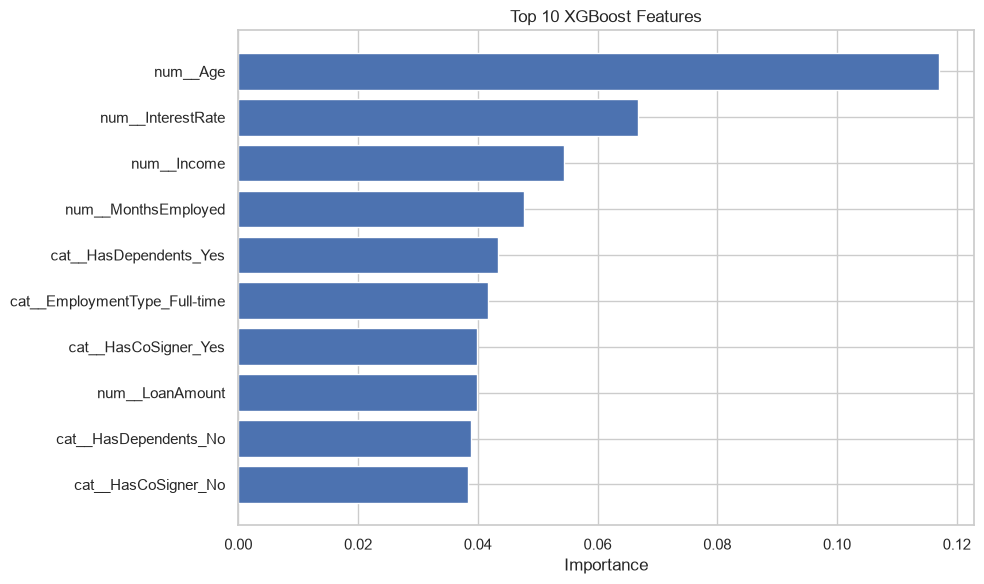

In [22]:
# Comparing feature importance from Random Forest and XGBoost.
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

xgb_preprocessor = xgboost_model.named_steps["preprocessor"]
xgb_classifier = xgboost_model.named_steps["classifier"]

rf_feature_names = rf_preprocessor.get_feature_names_out()
xgb_feature_names = xgb_preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Random Forest Importance": rf_classifier.feature_importances_
})

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "XGBoost Importance": xgb_classifier.feature_importances_
})

feature_importance_comparison = rf_importance.merge(
    xgb_importance, on="Feature", how="outer"
).fillna(0)

display(
    feature_importance_comparison.sort_values(
        "XGBoost Importance", ascending=False
    ).head(15).round(4)
)

# Plotting the top 10 features according to XGBoost.
top_xgb_features = feature_importance_comparison.nlargest(
    10, "XGBoost Importance"
).sort_values("XGBoost Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_xgb_features["Feature"], top_xgb_features["XGBoost Importance"])
plt.xlabel("Importance")
plt.title("Top 10 XGBoost Features")
plt.tight_layout()
plt.show()


## 15. Results and Discussion

The validation table compares five classification algorithms using the same validation records. The final test table reports the performance of the selected model on unseen records.

The best model is selected using validation F1-score, while precision, recall, ROC-AUC and average precision provide additional information. In a loan-default setting, a high accuracy value alone is not enough because the dataset contains fewer default cases than non-default cases.

The KNN result should be interpreted with its training-sample limitation in mind. It was fitted on a stratified sample of the training data to reduce computation time, while Logistic Regression, Naive Bayes, Random Forest and XGBoost used the full training set.

XGBoost also uses a class-weight adjustment through `scale_pos_weight` to give additional importance to the minority default class. Its performance is assessed using the same validation metrics as the other models.


In [23]:
# Displaying the validation ranking and final test score together.
validation_ranking = validation_comparison.sort_values(
    "Default F1-score", ascending=False
)
display(validation_ranking.round(4))

print(f"Selected model: {best_model_name}")
print(f"Test F1-score: {test_metrics['Default F1-score']:.4f}")
print(f"Test default recall: {test_metrics['Default Recall']:.4f}")
print(f"Test ROC-AUC: {test_metrics['ROC-AUC']:.4f}")

,Accuracy,Default Precision,Default Recall,Default F1-score,ROC-AUC,Average Precision
XGBoost,0.7047,0.2297,0.6554,0.3402,0.7528,0.3307
Logistic Regression,0.6747,0.2170,0.6905,0.3303,0.7495,0.3130
Naive Bayes,0.6677,0.2123,0.6868,0.3244,0.7422,0.3038
Random Forest,0.8680,0.3957,0.2589,0.3130,0.7496,0.3210
KNN,0.8794,0.3523,0.0459,0.0811,0.6317,0.1875


Selected model: XGBoost
Test F1-score: 0.3513
Test default recall: 0.6739
Test ROC-AUC: 0.7592


## 16. Conclusion

This project used supervised machine learning to predict loan default as a binary classification problem. The dataset was examined through data-quality checks and exploratory data analysis. Numerical and categorical features were then prepared using preprocessing pipelines.

Logistic Regression, K-Nearest Neighbours, Gaussian Naive Bayes, Random Forest and XGBoost were trained and compared. The validation set was used to select the model with the highest default-class F1-score. The selected model was then evaluated on a separate test set.

The final metrics show how well the selected model identifies default cases and how many non-defaulters it may incorrectly flag. These results can help explain the strengths and limitations of the model, but they do not establish that it is ready for real lending decisions.

## 17. Limitations and Future Scope

1. **Class imbalance:** Default cases are a minority, which can make them harder to identify.
2. **KNN training sample:** KNN was trained on a stratified subset to keep computation manageable. Its results may differ if trained on the full training set.
3. **Model assumptions:** Each algorithm has its own assumptions and limitations. Gaussian Naive Bayes assumes conditional independence between features, while tree-based ensemble models can be more difficult to interpret.
4. **Fairness and privacy:** The dataset and models would need further checks for bias, privacy, explainability and regulatory compliance before any real-world use.
5. **Further improvement:** Future work could include hyperparameter tuning, cross-validation, threshold selection based on lending costs and testing on a separate external dataset.

## 18. Dataset

Nikhil, *Loan Default Prediction Dataset*, Kaggle. https://www.kaggle.com/datasets/nikhil1e9/loan-default
